# Active transportation, diet quality, BMI, and systolic blood pressure

**Question:** Is active transportation associated with lower mean systolic BP after adjustment for age, self-rated diet quality, household income, sex, and race/ethnicity, and how much of the association is accounted for by BMI?

Exposure: active transportation **yes versus no** (`PAQ635`). Proposed mediator: BMI. Outcome: mean of available valid systolic readings. Both models use the same complete-case sample of adults aged 20–79 and the same control variables. Education, income-to-poverty ratio, and activity duration are not required for this specification.

The proposed pathway is **active transportation → BMI → SBP**, alongside other pathways from activity to BP. Lower BMI with activity is a hypothesis, not a constraint on the fitted models. The questionnaire combines walking and cycling in bouts of at least 10 continuous minutes during a typical week.

These cross-sectional data do not establish temporal ordering: BMI and health could also affect travel choices. Treating self-rated diet quality as a control assumes it is not a consequence of the exposure for the intended mediation interpretation. It is a subjective assessment, not a measured nutrient score.

Sources: [Physical activity](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/PAQ_J.htm), [diet quality](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DBQ_J.htm), [income codes](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DEMO_J.htm).


In [1]:
import statsmodels.api as sm

In [2]:
import pandas as pd
from pathlib import Path

# Data folder relative to this notebook in nhanes/memo.
data_dir = Path("../2017")

demo = pd.read_csv(data_dir / "DEMO_J.csv.gz")
bmx = pd.read_csv(data_dir / "BMX_J.csv.gz")
bpx = pd.read_csv(data_dir / "BPX_J.csv.gz")
biopro = pd.read_csv(data_dir / "BIOPRO_J.csv.gz")

# SEQN identifies the same participant across files.
df = demo.merge(bmx, on="SEQN", how="left")
df = df.merge(bpx, on="SEQN", how="left")
df = df.merge(biopro, on="SEQN", how="left")

df.head()

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,LBXSCA,LBDSCASI,LBXSCH,LBDSCHSI,LBXSTP,LBDSTPSI,LBXSTR,LBDSTRSI,LBXSUA,LBDSUASI
0,93703.0,10.0,2.0,2.0,2.0,NaN,5.0,6.0,2.0,27.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,93704.0,10.0,2.0,1.0,2.0,NaN,3.0,3.0,1.0,33.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,93705.0,10.0,2.0,2.0,66.0,NaN,4.0,4.0,2.0,NaN,...,9.2,2.300,157.0,4.060,7.3,73.0,95.0,1.073,5.8,345.0
3,93706.0,10.0,2.0,1.0,18.0,NaN,5.0,6.0,2.0,222.0,...,9.6,2.400,149.0,3.853,7.1,71.0,92.0,1.039,8.0,475.8
4,93707.0,10.0,2.0,1.0,13.0,NaN,5.0,7.0,2.0,158.0,...,10.1,2.525,199.0,5.146,8.0,80.0,110.0,1.242,5.5,327.1


In [3]:
# Keep the requested variables, preserving their original NHANES names.
columns = [
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU",  # Survey weight, stratum, PSU
    "SEQN",  # Participant ID
    "BPXSY1",
    "BPXSY2",
    "BPXSY3",
    "BPXSY4",  # Systolic BP readings (mmHg)
    "RIDAGEYR",  # Age in years (80 means 80+)
    "BMXBMI",  # BMI (kg/m²)
    "DMDEDUC2",  # Education level, adults 20+
    "INDFMPIR",  # Family income / poverty threshold
    "INDFMIN2",  # Annual family income category
    "INDHHIN2",  # Annual household income category
    "RIDRETH3",  # Race/ethnicity, including NH Asian
    "RIAGENDR",  # Sex
]
data = df[columns].copy()

# Occupation is not included in the four base files.
data.head()

,WTMEC2YR,SDMVSTRA,SDMVPSU,SEQN,BPXSY1,BPXSY2,BPXSY3,BPXSY4,RIDAGEYR,BMXBMI,DMDEDUC2,INDFMPIR,INDFMIN2,INDHHIN2,RIDRETH3,RIAGENDR
0,8539.731348,145.0,2.0,93703.0,NaN,NaN,NaN,NaN,2.0,17.5,NaN,5.00,15.0,15.0,6.0,2.0
1,42566.614750,143.0,1.0,93704.0,NaN,NaN,NaN,NaN,2.0,15.7,NaN,5.00,15.0,15.0,3.0,1.0
2,8338.419786,145.0,2.0,93705.0,NaN,NaN,202.0,198.0,66.0,31.7,2.0,0.82,3.0,3.0,4.0,2.0
3,8723.439814,134.0,2.0,93706.0,112.0,114.0,108.0,NaN,18.0,21.5,NaN,NaN,NaN,NaN,6.0,1.0
4,7064.609730,138.0,1.0,93707.0,128.0,128.0,128.0,NaN,13.0,18.1,NaN,1.88,10.0,10.0,7.0,1.0


## Add transportation activity

`PAQ635`: 1 = yes, 2 = no. `PAQ640`: days per typical week. `PAD645`: minutes on a typical active day.

Weekly minutes = days × minutes. Confirmed nonparticipants get zero weekly minutes; participants with unknown frequency or duration remain missing. The adult activity questionnaire starts at age 18, while the education field starts at age 20. No participant filters are applied yet.


In [4]:
# Download once, then reuse the local file.
activity_file = data_dir / "PAQ_J.csv.gz"
if not activity_file.exists():
    from io import BytesIO
    import requests

    url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/PAQ_J.xpt"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    paq = pd.read_sas(BytesIO(response.content), format="xport")
    paq.to_csv(activity_file, index=False)

paq = pd.read_csv(activity_file)
transport_columns = ["PAQ635", "PAQ640", "PAD645"]
# Start from the selected base columns so rerunning this cell does not duplicate columns.
data = df[columns].merge(
    paq[["SEQN"] + transport_columns], on="SEQN", how="left", validate="one_to_one"
)

In [5]:
# Unknown/ineligible responses remain missing; only an explicit "no" becomes zero.
data["active_transport"] = data["PAQ635"].map({1: 1, 2: 0})
days = data["PAQ640"].where(data["PAQ640"].between(1, 7))
minutes = data["PAD645"].where(data["PAD645"].between(10, 1439))
data["transport_min_week"] = (days * minutes).where(data["active_transport"].eq(1))
data.loc[data["active_transport"].eq(0), "transport_min_week"] = 0
data["transport_hours_week"] = data["transport_min_week"] / 60

sbp_readings = data[["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"]]
data["mean_sbp"] = sbp_readings.where(sbp_readings > 0).mean(axis=1)

data[
    ["mean_sbp", "RIDAGEYR", "BMXBMI", "active_transport", "transport_min_week"]
].head()

,mean_sbp,RIDAGEYR,BMXBMI,active_transport,transport_min_week
0,NaN,2.0,17.5,NaN,NaN
1,NaN,2.0,15.7,NaN,NaN
2,200.000000,66.0,31.7,0.0,0.0
3,111.333333,18.0,21.5,1.0,225.0
4,128.000000,13.0,18.1,NaN,NaN


## Age–activity interaction

Both models include activity, age, and activity × age-basis interactions. Each model uses the age spline with the lowest AIC: a five-df cubic B-spline for SBP and a four-df cubic B-spline for BMI. All controls stay in every candidate. In the SBP model, AIC selects a linear BMI term with an **activity × BMI interaction**, so the BMI–SBP slope may differ between active and inactive participants. No BMI × age interaction is fitted, so within each activity group the slope is assumed constant across ages. That is a substantive limitation, not a demonstrated biological fact.

The BMI model includes age, income, sex, and race/ethnicity as well as diet and activity. Omitting these potential confounders from the mediator model would leave its activity–BMI comparison differently adjusted from the outcome model. Using a common adjustment set is a starting specification; it does not establish that all causal confounding is controlled.

Household income is collapsed to three groups: low (<$20k), medium ($20k–74,999), and high (≥$75k). NHANES code 12 ("$20,000 and over") spans the medium and high groups and is treated as missing. Diet, income, sex, and race/ethnicity enter as categories. Their numeric codes are labels, not continuous scales. Correlation among predictors is allowed; high collinearity can reduce precision, whereas confounding concerns the causal relationships among them. Complete-case selection can also affect interpretation if excluded participants differ systematically.


## Add self-rated diet quality

`DBQ700`: 1 = excellent, 2 = very good, 3 = good, 4 = fair, 5 = poor. Refused/unknown codes become missing. All original records remain in `data`; exclusions are applied only to the model sample `cc`.


In [6]:
diet_file = data_dir / "DBQ_J.csv.gz"
if not diet_file.exists():
    from io import BytesIO
    import requests

    url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/DBQ_J.xpt"
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    dbq = pd.read_sas(BytesIO(response.content), format="xport")
    dbq.to_csv(diet_file, index=False)

dbq = pd.read_csv(diet_file)
data = data.drop(columns="DBQ700", errors="ignore").merge(
    dbq[["SEQN", "DBQ700"]], on="SEQN", how="left", validate="one_to_one"
)

In [7]:
# A common complete-case sample for BOTH models.
adults = data.loc[data["RIDAGEYR"].between(20, 79)].copy()
adults["DBQ700"] = adults["DBQ700"].where(adults["DBQ700"].isin([1, 2, 3, 4, 5]))
# Household income in three groups: 1 = Low (<$20k), 2 = Medium ($20k–74,999), 3 = High (≥$75k).
# Code 13 ("under $20,000") is Low. Code 12 ("$20,000 and over") spans Medium and High,
# so it is set to missing, as are 77/99 (refused/don't know).
income_groups = {
    1: 1,
    2: 1,
    3: 1,
    4: 1,
    13: 1,
    5: 2,
    6: 2,
    7: 2,
    8: 2,
    9: 2,
    10: 2,
    14: 3,
    15: 3,
}
adults["income_group"] = adults["INDHHIN2"].map(income_groups)
adults["RIAGENDR"] = adults["RIAGENDR"].where(adults["RIAGENDR"].isin([1, 2]))
adults["RIDRETH3"] = adults["RIDRETH3"].where(
    adults["RIDRETH3"].isin([1, 2, 3, 4, 6, 7])
)
adults["BMXBMI"] = adults["BMXBMI"].where(adults["BMXBMI"] > 0)

model_columns = [
    "mean_sbp",
    "BMXBMI",
    "DBQ700",
    "active_transport",
    "RIDAGEYR",
    "income_group",
    "RIAGENDR",
    "RIDRETH3",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU",
]
cc = adults.dropna(subset=model_columns).loc[lambda x: x["WTMEC2YR"] > 0].copy()
# Do not drop on education, dietary intake, activity duration, or all four BP readings.
print(f"Adults aged 20–79: {len(adults):,}; complete cases: {len(cc):,}")
display(
    cc["income_group"]
    .map({1: "Low", 2: "Medium", 3: "High"})
    .value_counts()
    .rename("Participants")
)
display(
    cc["active_transport"]
    .map({0: "No", 1: "Yes"})
    .value_counts()
    .rename("Participants")
)

Adults aged 20–79: 5,142; complete cases: 4,014


income_group
Medium    1999
High      1263
Low        752
Name: Participants, dtype: int64

active_transport
No     3044
Yes     970
Name: Participants, dtype: int64

## Compare spline complexity by AIC

Keep diet quality, household income, sex, race/ethnicity, and the active-transportation terms in **every** candidate. Use the identical complete-case sample throughout.

- Age: linear or a cubic B-spline with 3, 4, 5, or 6 basis columns. Retain activity × the entire age basis.
- BMI in the SBP model: linear, linear with an activity × BMI interaction, or a small natural cubic spline with 3 or 4 basis columns. No candidate has a BMI × age term.
- BMI mediator model: compare the five age choices, keeping the same response, exposure, and controls.

This gives 20 SBP candidates and five BMI candidates. AIC values are compared **within each response**, not between SBP and BMI models. Smaller is better; ΔAIC is relative to the best candidate for that response. Near ties indicate model uncertainty, not a decisive winner. Degrees of freedom count basis columns, not knots. AIC is a fit/complexity criterion, not a hypothesis test.

Selection uses ordinary Gaussian **OLS AIC**, as an exploratory working-model comparison, not a survey-adjusted AIC. The selected formulas are subsequently fitted with examination weights. Survey intervals condition on the selected structures and knots; the AIC search is not repeated within replicates.

**Final choice:** For each response, use the candidate with the lowest AIC. For SBP, that is `bs(RIDAGEYR, 5)` with linear BMI and activity × BMI. For BMI, it is `bs(RIDAGEYR, 4)`. A cubic B-spline with _k_ df has _k_ − 3 interior knots at age quantiles: two for SBP and one for BMI. The individual spline coefficients are not interpretable on their own; the age-specific contrasts below are the quantities of interest. The `chosen` column records the model used for analysis.


In [8]:
controls = "C(DBQ700) + C(income_group) + C(RIAGENDR) + C(RIDRETH3)"
age_options = {"Linear": "RIDAGEYR"}
for df_age in [3, 4, 5, 6]:
    age_options[f"B-spline {df_age} df"] = f"bs(RIDAGEYR, {df_age})"
bmi_options = {
    "Linear": "BMXBMI",
    "Linear + activity × BMI": "BMXBMI + active_transport:BMXBMI",
    "Natural spline 3 df": 'cr(BMXBMI, df=3, constraints="center")',
    "Natural spline 4 df": 'cr(BMXBMI, df=4, constraints="center")',
}

sbp_rows, bmi_rows = [], []
for age_label, age_term in age_options.items():
    for bmi_label, bmi_term in bmi_options.items():
        formula = f"mean_sbp ~ {bmi_term} + active_transport * {age_term} + {controls}"
        candidate = sm.OLS.from_formula(formula, data=cc).fit()
        sbp_rows.append({
            "Age": age_label,
            "BMI": bmi_label,
            "n": int(candidate.nobs),
            "AIC": candidate.aic,
            "formula": formula,
        })
    formula = f"BMXBMI ~ active_transport * {age_term} + {controls}"
    candidate = sm.OLS.from_formula(formula, data=cc).fit()
    bmi_rows.append({
        "Age": age_label,
        "n": int(candidate.nobs),
        "AIC": candidate.aic,
        "formula": formula,
    })

sbp_aic = pd.DataFrame(sbp_rows).sort_values("AIC").reset_index(drop=True)
bmi_aic = pd.DataFrame(bmi_rows).sort_values("AIC").reset_index(drop=True)
sbp_aic["delta_AIC"] = sbp_aic["AIC"] - sbp_aic["AIC"].min()
bmi_aic["delta_AIC"] = bmi_aic["AIC"] - bmi_aic["AIC"].min()

# Choice: the lowest-AIC candidate for each response.
sbp_aic["chosen"] = sbp_aic["AIC"].eq(sbp_aic["AIC"].min())
bmi_aic["chosen"] = bmi_aic["AIC"].eq(bmi_aic["AIC"].min())

results_dir = Path("active_transport_results")
results_dir.mkdir(exist_ok=True)
sbp_aic.to_csv(results_dir / "sbp_spline_aic.csv", index=False)
bmi_aic.to_csv(results_dir / "bmi_spline_aic.csv", index=False)
print("SBP model comparison — fixed controls, no BMI × age interaction")
display(sbp_aic.drop(columns="formula").round(2))
print("BMI mediator model comparison — fixed controls")
display(bmi_aic.drop(columns="formula").round(2))

SBP model comparison — fixed controls, no BMI × age interaction


,Age,BMI,n,AIC,delta_AIC,chosen
0,B-spline 5 df,Linear + activity × BMI,4014,33950.65,0.00,True
1,B-spline 3 df,Linear + activity × BMI,4014,33951.90,1.24,False
2,B-spline 6 df,Linear + activity × BMI,4014,33952.23,1.57,False
3,B-spline 5 df,Linear,4014,33952.62,1.96,False
4,B-spline 4 df,Linear + activity × BMI,4014,33953.36,2.70,False
5,B-spline 6 df,Linear,4014,33953.98,3.33,False
6,B-spline 3 df,Linear,4014,33954.04,3.39,False
7,B-spline 4 df,Linear,4014,33955.36,4.71,False
8,B-spline 5 df,Natural spline 3 df,4014,33956.57,5.92,False
9,B-spline 5 df,Natural spline 4 df,4014,33957.83,7.18,False


BMI mediator model comparison — fixed controls


,Age,n,AIC,delta_AIC,chosen
0,B-spline 4 df,4014,27076.85,0.00,True
1,B-spline 3 df,4014,27077.08,0.22,False
2,B-spline 5 df,4014,27078.87,2.02,False
3,B-spline 6 df,4014,27079.67,2.81,False
4,Linear,4014,27117.85,41.00,False


## Fit the two models

`active_transport` is coded 1 = yes and 0 = no, so contrasts compare participants with nonparticipants. With interactions, the activity coefficient alone is not the activity contrast at every age; use the prediction contrasts below. `C(...)` expands categories into indicator variables. Examination weights are appropriate because the analysis combines interview variables with BP and BMI measurements.

The table below shows point estimates only; survey bootstrap uncertainty is added further down.


In [9]:
# Use the lowest-AIC model for each response.
sbp_formula = sbp_aic.loc[sbp_aic["chosen"], "formula"].iloc[0]
bmi_formula = bmi_aic.loc[bmi_aic["chosen"], "formula"].iloc[0]

sbp_model = sm.WLS.from_formula(sbp_formula, data=cc, weights=cc["WTMEC2YR"]).fit()
bmi_model = sm.WLS.from_formula(bmi_formula, data=cc, weights=cc["WTMEC2YR"]).fit()

print("Chosen SBP model:", sbp_formula)
print("Chosen BMI model:", bmi_formula)
display(
    pd.concat(
        {"SBP coefficient": sbp_model.params, "BMI coefficient": bmi_model.params},
        axis=1,
    )
)

Chosen SBP model: mean_sbp ~ BMXBMI + active_transport:BMXBMI + active_transport * bs(RIDAGEYR, 5) + C(DBQ700) + C(income_group) + C(RIAGENDR) + C(RIDRETH3)
Chosen BMI model: BMXBMI ~ active_transport * bs(RIDAGEYR, 4) + C(DBQ700) + C(income_group) + C(RIAGENDR) + C(RIDRETH3)


,SBP coefficient,BMI coefficient
Intercept,101.086283,22.998889
C(DBQ700)[T.2.0],-0.341156,1.783824
C(DBQ700)[T.3.0],0.910396,3.874305
C(DBQ700)[T.4.0],2.292014,5.832183
C(DBQ700)[T.5.0],2.527017,6.798522
C(income_group)[T.2.0],-0.916280,1.167164
C(income_group)[T.3.0],-3.445890,0.776787
C(RIAGENDR)[T.2.0],-3.703439,0.249550
C(RIDRETH3)[T.2.0],1.410455,-0.941551
C(RIDRETH3)[T.3.0],0.433605,-0.807078


## Survey bootstrap

The bootstrap and mediation estimator are written as functions so that the 2015–2016 holdout below goes through identical code.

Uncertainty comes from a nonparametric bootstrap that respects the NHANES design. Resampling individuals would ignore clustering and understate the uncertainty, so whole PSUs are resampled within strata: the **Rao–Wu rescaling bootstrap**. In each stratum with _n_h_ PSUs, draw _n_h_ − 1 PSUs with replacement and multiply their examination weights by _n_h_/(_n_h_ − 1) × (times drawn). This cycle has two PSUs per stratum, so each replicate keeps one PSU per stratum at double weight.

Each replicate refits **both** models on the same bootstrap weights, so their dependence carries into the mediation effects. The formulas and spline knots stay fixed at the full-sample choice; the AIC search is not repeated inside replicates. Intervals are 95% percentile intervals from B = 2,000 replicates.


In [10]:
import time

import numpy as np
from patsy import build_design_matrices

B = 2000


def survey_bootstrap(frame, design, sbp_y, sbp_X, bmi_y, bmi_X, seed, n_boot=B):
    """Fit both models on one cycle and refit them on Rao–Wu survey bootstrap weights.

    frame: complete-case sample; design: that cycle's strata/PSUs from the full
    demographics file (so the sample is treated as a domain). The design matrices
    are fixed: formulas and spline knots are not re-chosen inside replicates.
    """
    rng = np.random.default_rng(seed)
    weights = frame["WTMEC2YR"].to_numpy()
    strata, psu = frame["SDMVSTRA"].to_numpy(), frame["SDMVPSU"].to_numpy()
    groups = [
        (
            group["SDMVPSU"].to_numpy(),
            {p: (strata == h) & (psu == p) for p in group["SDMVPSU"]},
        )
        for h, group in design.groupby("SDMVSTRA")
    ]
    full_sbp = sm.WLS(sbp_y, sbp_X, weights=weights).fit()
    full_bmi = sm.WLS(bmi_y, bmi_X, weights=weights).fit()

    def bootstrap_weights():
        """In each stratum, draw n_h − 1 PSUs with replacement; rescale by n_h / (n_h − 1)."""
        multiplier = np.zeros(len(frame))
        for psus, masks in groups:
            n_h = len(psus)
            draws = rng.choice(psus, size=n_h - 1, replace=True)
            for p in psus:
                multiplier[masks[p]] = n_h / (n_h - 1) * np.sum(draws == p)
        return weights * multiplier

    def fit_both(w):
        sbp_fit = sm.WLS(sbp_y, sbp_X, weights=w).fit()
        bmi_fit = sm.WLS(bmi_y, bmi_X, weights=w).fit()
        if (
            sbp_fit.model.rank != full_sbp.model.rank
            or bmi_fit.model.rank != full_bmi.model.rank
        ):
            raise ValueError(
                "A bootstrap replicate lost model rank; inspect sparse categories."
            )
        # Residual SD of BMI given covariates, for drawing BMI from P̂(M | X).
        resid = bmi_fit.model.endog - bmi_fit.fittedvalues
        return (
            np.asarray(sbp_fit.params),
            np.asarray(bmi_fit.params),
            np.sqrt(np.sum(w * resid**2) / np.sum(w)),
        )

    start = time.time()
    point_sbp, point_bmi, point_sd = fit_both(weights)
    out = {
        "frame": frame,
        "weights": weights,
        "rng": rng,
        "sbp_fit": full_sbp,
        "bmi_fit": full_bmi,
        "sbp_names": list(sbp_X.columns),
        "bmi_names": list(bmi_X.columns),
        "point_sbp": point_sbp,
        "point_bmi": point_bmi,
        "point_sd": point_sd,
        "boot_weights": np.empty((len(frame), n_boot)),
        "boot_sbp": np.empty((n_boot, len(point_sbp))),
        "boot_bmi": np.empty((n_boot, len(point_bmi))),
        "boot_sd": np.empty(n_boot),
    }
    for b in range(n_boot):
        out["boot_weights"][:, b] = bootstrap_weights()
        out["boot_sbp"][b], out["boot_bmi"][b], out["boot_sd"][b] = fit_both(
            out["boot_weights"][:, b]
        )
    print(
        f"{n_boot} bootstrap replicates in {time.time() - start:.0f} s; "
        f"{design['SDMVSTRA'].nunique()} strata, {len(design)} PSUs; BMI residual SD = {point_sd:.2f} kg/m²"
    )
    return out


# Freeze the selected models: formulas, categorical coding, and spline knots.
sbp_spec = sbp_model.model.data.model_spec
bmi_spec = bmi_model.model.data.model_spec


def model_matrices(frame):
    """Responses and design matrices from the frozen 2017 specifications."""
    X_sbp = build_design_matrices([sbp_spec], frame, return_type="dataframe")[0]
    X_bmi = build_design_matrices([bmi_spec], frame, return_type="dataframe")[0]
    return frame["mean_sbp"], X_sbp, frame["BMXBMI"], X_bmi


design_2017 = demo[["SDMVSTRA", "SDMVPSU"]].drop_duplicates().dropna()
boot_2017 = survey_bootstrap(cc, design_2017, *model_matrices(cc), seed=604)
np.testing.assert_allclose(boot_2017["point_sbp"], sbp_model.params, rtol=1e-10)

2000 bootstrap replicates in 9 s; 15 strata, 30 PSUs; BMI residual SD = 6.88 kg/m²


### Coefficient tables

Estimates are examination-weighted; SEs and 95% percentile intervals come from the survey bootstrap. Category terms are contrasts with the reference levels: excellent diet, low household income, male, Mexican American.

**Reading the spline and interaction terms:** The B-spline basis columns are zero at age 20, so `active_transport` alone is the yes-vs-no contrast **at age 20** (in the SBP model also at BMI = 0, an extrapolation with no direct meaning). The individual basis and Active × basis coefficients have no standalone interpretation; the mediation effects below summarize them.


In [11]:
import re

diet_labels = {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}
income_labels = {1: "Low (<$20k)", 2: "Medium ($20k–74,999)", 3: "High (≥$75k)"}
race_labels = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other/multiracial",
}
sex_labels = {1: "Male", 2: "Female"}
term_labels = {
    "DBQ700": ("Diet quality", diet_labels),
    "income_group": ("Household income", income_labels),
    "RIAGENDR": ("Sex", sex_labels),
    "RIDRETH3": ("Race/ethnicity", race_labels),
}


def describe_term(name):
    match = re.fullmatch(r"C\((\w+)\)\[T\.([\d.]+)\]", name)
    if match:
        variable, labels = term_labels[match.group(1)]
        return f"{variable}: {labels[int(float(match.group(2)))]}"
    return {
        "Intercept": "Intercept",
        "BMXBMI": "BMI (per kg/m²; inactive group in the SBP model)",
        "active_transport:BMXBMI": "Active × BMI (difference in BMI slope, active − inactive)",
        # B-spline basis columns are zero at the lowest age; with the Active × BMI term in the
        # SBP model, this is the contrast at age 20 and BMI = 0, an extrapolation.
        "active_transport": "Active transport (yes vs no) at age 20 (SBP model: also at BMI = 0)",
    }.get(
        name,
        re.sub(r"bs\(RIDAGEYR, \d+\)", "age basis", name).replace(
            "active_transport:", "Active × "
        ),
    )


def coefficient_table(names, point, replicates):
    lower, upper = np.percentile(replicates, [2.5, 97.5], axis=0)
    return pd.DataFrame(
        {
            "term": [describe_term(n) for n in names],
            "estimate": point,
            "bootstrap_SE": replicates.std(axis=0, ddof=1),
            "lower_95": lower,
            "upper_95": upper,
        },
        index=pd.Index(names, name="coefficient"),
    )


def coefficient_tables(boot, out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    sbp = coefficient_table(boot["sbp_names"], boot["point_sbp"], boot["boot_sbp"])
    bmi = coefficient_table(boot["bmi_names"], boot["point_bmi"], boot["boot_bmi"])
    sbp.to_csv(out_dir / "sbp_coefficients.csv")
    bmi.to_csv(out_dir / "bmi_coefficients.csv")
    print(
        "Outcome model: mean SBP (mmHg). Survey bootstrap SEs and percentile 95% intervals."
    )
    display(sbp.round(3))
    print(
        "Mediator model: BMI (kg/m²). Survey bootstrap SEs and percentile 95% intervals."
    )
    display(bmi.round(3))
    return sbp, bmi


sbp_coefficients, bmi_coefficients = coefficient_tables(boot_2017, results_dir)

Outcome model: mean SBP (mmHg). Survey bootstrap SEs and percentile 95% intervals.


,term,estimate,bootstrap_SE,lower_95,upper_95
coefficient,,,,,
Intercept,Intercept,101.086,3.049,94.835,106.577
C(DBQ700)[T.2.0],Diet quality: Very good,-0.341,1.432,-3.415,2.128
C(DBQ700)[T.3.0],Diet quality: Good,0.910,1.331,-1.827,3.456
C(DBQ700)[T.4.0],Diet quality: Fair,2.292,1.206,-0.202,4.442
C(DBQ700)[T.5.0],Diet quality: Poor,2.527,1.087,0.250,4.472
C(income_group)[T.2.0],"Household income: Medium ($20k–74,999)",-0.916,1.031,-2.768,1.185
C(income_group)[T.3.0],Household income: High (≥$75k),-3.446,1.397,-5.996,-0.592
C(RIAGENDR)[T.2.0],Sex: Female,-3.703,0.692,-5.080,-2.385
C(RIDRETH3)[T.2.0],Race/ethnicity: Other Hispanic,1.410,0.806,-0.035,3.050


Mediator model: BMI (kg/m²). Survey bootstrap SEs and percentile 95% intervals.


,term,estimate,bootstrap_SE,lower_95,upper_95
coefficient,,,,,
Intercept,Intercept,22.999,0.812,21.489,24.643
C(DBQ700)[T.2.0],Diet quality: Very good,1.784,0.715,0.488,3.321
C(DBQ700)[T.3.0],Diet quality: Good,3.874,0.656,2.680,5.269
C(DBQ700)[T.4.0],Diet quality: Fair,5.832,0.530,4.810,6.883
C(DBQ700)[T.5.0],Diet quality: Poor,6.799,0.778,5.344,8.347
C(income_group)[T.2.0],"Household income: Medium ($20k–74,999)",1.167,0.350,0.479,1.787
C(income_group)[T.3.0],Household income: High (≥$75k),0.777,0.432,0.039,1.678
C(RIAGENDR)[T.2.0],Sex: Female,0.250,0.377,-0.498,1.015
C(RIDRETH3)[T.2.0],Race/ethnicity: Other Hispanic,-0.942,0.473,-1.773,0.046


## Model selection summary

All candidates from the AIC grid are shown with parameter count, ΔAIC, **Akaike weights** (relative support within each response, summing to 1). Selection was by AIC on unweighted OLS fits on the common complete-case sample (n = 4,014). AIC is never compared across the SBP and BMI responses.

Rule: Use the lowest AIC for each response.

- **SBP model:** The 5-df age B-spline with linear BMI and an activity × BMI interaction has the lowest AIC. Adding the interaction improves AIC by about 2 at every age specification, and linear BMI beats the natural-spline BMI options. Linear age is clearly worse.
- **BMI mediator model:** The 4-df age B-spline has the lowest AIC. Linear age is clearly worse (ΔAIC ≈ 41).

Several spline sizes are within about 2 AIC units of each other, so the data do not sharply distinguish them. The choice mainly affects the shape of the age curves, especially at the ends of the age range.


In [12]:
selection_rows = []
for response, table in [("SBP", sbp_aic), ("BMI", bmi_aic)]:
    for _, row in table.iterrows():
        fit = sm.OLS.from_formula(row["formula"], data=cc).fit()
        selection_rows.append({
            "response": response,
            "Age": row["Age"],
            "BMI": row.get("BMI", "—"),
            "parameters": int(fit.df_model + 1),
            "AIC": fit.aic,
            "chosen": row["chosen"],
        })
selection = pd.DataFrame(selection_rows)
selection["delta_AIC"] = selection["AIC"] - selection.groupby("response")[
    "AIC"
].transform("min")
selection["akaike_weight"] = np.exp(-selection["delta_AIC"] / 2)
selection["akaike_weight"] /= selection.groupby("response")["akaike_weight"].transform(
    "sum"
)
selection = selection.sort_values(
    ["response", "AIC"], ascending=[False, True]
).reset_index(drop=True)
selection.to_csv(results_dir / "model_selection_summary.csv", index=False)
display(
    selection[
        [
            "response",
            "Age",
            "BMI",
            "parameters",
            "AIC",
            "delta_AIC",
            "akaike_weight",
            "chosen",
        ]
    ].round(3)
)

,response,Age,BMI,parameters,AIC,delta_AIC,akaike_weight,chosen
0,SBP,B-spline 5 df,Linear + activity × BMI,26,33950.654,0.000,0.305,True
1,SBP,B-spline 3 df,Linear + activity × BMI,22,33951.897,1.243,0.164,False
2,SBP,B-spline 6 df,Linear + activity × BMI,28,33952.227,1.572,0.139,False
3,SBP,B-spline 5 df,Linear,25,33952.615,1.961,0.115,False
4,SBP,B-spline 4 df,Linear + activity × BMI,24,33953.356,2.702,0.079,False
5,SBP,B-spline 6 df,Linear,27,33953.982,3.328,0.058,False
6,SBP,B-spline 3 df,Linear,21,33954.040,3.386,0.056,False
7,SBP,B-spline 4 df,Linear,23,33955.362,4.708,0.029,False
8,SBP,B-spline 5 df,Natural spline 3 df,27,33956.569,5.915,0.016,False
9,SBP,B-spline 5 df,Natural spline 4 df,28,33957.833,7.178,0.008,False


### Fit statistics for the chosen models

Survey-weighted fits of the selected formulas. R² and residual SD use examination weights; AIC is the OLS selection criterion from the grid. Weighted N is the sum of examination weights, estimating the U.S. population represented by the complete-case domain.


In [13]:
def fit_summary(label, model, aic_table):
    chosen = aic_table.loc[aic_table["chosen"]].iloc[0]
    resid = model.model.endog - model.fittedvalues
    w = model.model.weights
    return {
        "model": label,
        "n": int(model.nobs),
        "weighted N (population)": w.sum(),
        "parameters": int(model.df_model + 1),
        "weighted R²": model.rsquared,
        "weighted adj. R²": model.rsquared_adj,
        "weighted residual SD": np.sqrt(np.sum(w * resid**2) / w.sum()),
        "OLS AIC": chosen["AIC"],
    }


model_fit = (
    pd
    .DataFrame([
        fit_summary("SBP (mmHg)", sbp_model, sbp_aic),
        fit_summary("BMI (kg/m²)", bmi_model, bmi_aic),
    ])
    .set_index("model")
    .T
)
model_fit.to_csv(results_dir / "model_fit_summary.csv")
display(
    model_fit.map(
        lambda v: f"{v:,.0f}" if abs(v) >= 1000 or float(v).is_integer() else f"{v:.3f}"
    )
)

model,SBP (mmHg),BMI (kg/m²)
n,"4,014","4,014"
weighted N (population),"194,438,516","194,438,516"
parameters,26,22
weighted R²,0.239,0.108
weighted adj. R²,0.234,0.104
weighted residual SD,14.881,6.877
OLS AIC,"33,951","27,077"


## Mediation: direct, indirect, and total effects

Let *x*₀ = no active transport and *x*₁ = yes. Following the class definitions, each effect is estimated **directly** from its own pair of counterfactual means:

- **Direct** (17): E[Y(M = M(x₀), X = x₁) − Y(M = M(x₀), X = x₀)]
- **Indirect** (18): E[Y(M = M(x₁), X = x₀) − Y(M = M(x₀), X = x₀)]
- **Total** (19): E[Y(M = M(x₁), X = x₁) − Y(M = M(x₀), X = x₀)]

**Imputation:** For each participant, keep their observed covariates, set X = x. Draw BMI M(x) from the fitted mediator model P̂(M | X = x, covariates), taken as normal with the weighted residual SD. Then impute Y from the fitted outcome model E[Y | X, M, covariates]. Averages use examination weights. Within a replicate, M(x₀) and M(x₁) share the same standard-normal draw (common random numbers). This reduces Monte Carlo noise and does not change any of the three expectations, which each involve one counterfactual BMI at a time.

**Uncertainty:** For each bootstrap replicate, refit both models and redo the imputation with fresh BMI draws (the class notes' "bootstrap the data for each imputation"). The point estimate uses 200 BMI draws per participant from the full-sample fit.

Nothing forces total = direct + indirect. Whether it holds depends on the fitted outcome model. With no activity × BMI interaction, direct + indirect would equal the total exactly. The chosen model includes that interaction, so they differ. The gap is the interaction coefficient times the BMI difference: the extra SBP change from the BMI shift occurring under active rather than inactive transport. The code requires the outcome model to be linear in BMI (interactions with BMI allowed) and stops if it is not.


In [14]:
def counterfactual_designs(frame):
    """Design matrices for the BMI and SBP models with exposure set to x = 0 and x = 1.

    The SBP design is written as A + M·D, which requires the outcome model to be linear
    in BMI (interactions with BMI are allowed). This is checked, not assumed.
    """
    designs = {}
    for x in (0, 1):
        f = frame.assign(active_transport=x)
        X_bmi = np.asarray(
            build_design_matrices([bmi_model.model.data.model_spec], f)[0]
        )
        sbp_at = [
            np.asarray(
                build_design_matrices(
                    [sbp_model.model.data.model_spec], f.assign(BMXBMI=float(m))
                )[0]
            )
            for m in (0, 1, 2)
        ]
        A, D = sbp_at[0], sbp_at[1] - sbp_at[0]
        if not np.allclose(sbp_at[2], A + 2 * D):
            raise ValueError(
                "The SBP model is not linear in BMI; this imputation code needs revising."
            )
        designs[x] = (X_bmi, A, D)
    return designs


def mediation_effects(designs, beta_sbp, beta_bmi, bmi_sd, weights, eta):
    """Imputation estimates of equations (17)–(19), with columns = replicates or draws.

    beta_sbp: (p_y, R); beta_bmi: (p_m, R); bmi_sd: (R,); weights, eta: (n, R).
    M(x) is a draw from the fitted normal model P̂(M | X = x, covariates).
    """

    def draw_bmi(x):
        return designs[x][0] @ beta_bmi + eta * bmi_sd

    def outcome(x, m):  # E[Y | X = x, M = m, covariates]
        _, A, D = designs[x]
        return A @ beta_sbp + m * (D @ beta_sbp)

    m0, m1 = draw_bmi(0), draw_bmi(1)
    y_m0_x0 = outcome(0, m0)  # Y(M = M(x0), X = x0)
    y_m0_x1 = outcome(1, m0)  # Y(M = M(x0), X = x1)
    y_m1_x0 = outcome(0, m1)  # Y(M = M(x1), X = x0)
    y_m1_x1 = outcome(1, m1)  # Y(M = M(x1), X = x1)

    def mean(v):
        return (weights * v).sum(axis=0) / weights.sum(axis=0)

    return {
        "direct": mean(y_m0_x1 - y_m0_x0),  # (17)
        "indirect": mean(y_m1_x0 - y_m0_x0),  # (18)
        "total": mean(y_m1_x1 - y_m0_x0),  # (19)
        "bmi_difference": mean(m1 - m0),
    }


effects = ["total", "direct", "indirect", "bmi_difference"]
point_draws = 200  # imputation draws per person for the point estimate
chunk = 250


def estimate_with_intervals(frame, boot):
    """Point estimate (many imputation draws) and bootstrap replicates (fresh draws each).

    frame: the cycle's sample, possibly with age reset; boot: output of survey_bootstrap.
    """
    rng = boot["rng"]
    designs = counterfactual_designs(frame)
    n, n_boot = len(frame), len(boot["boot_sd"])
    eta = rng.standard_normal((n, point_draws))
    point = mediation_effects(
        designs,
        np.repeat(boot["point_sbp"][:, None], point_draws, 1),
        np.repeat(boot["point_bmi"][:, None], point_draws, 1),
        np.repeat(boot["point_sd"], point_draws),
        np.repeat(boot["weights"][:, None], point_draws, 1),
        eta,
    )
    point = {k: v.mean() for k, v in point.items()}
    replicates = {k: [] for k in effects}
    for s in range(0, n_boot, chunk):
        cols = slice(s, min(s + chunk, n_boot))
        reps = mediation_effects(
            designs,
            boot["boot_sbp"][cols].T,
            boot["boot_bmi"][cols].T,
            boot["boot_sd"][cols],
            boot["boot_weights"][:, cols],
            rng.standard_normal((n, cols.stop - cols.start)),
        )
        for k in effects:
            replicates[k].append(reps[k])
    replicates = {k: np.concatenate(v) for k, v in replicates.items()}
    return point, replicates


def summarize(point, replicates):
    rows = []
    for k in effects:
        lower, upper = np.percentile(replicates[k], [2.5, 97.5])
        rows.append({
            "effect": k,
            "estimate": point[k],
            "bootstrap_SE": replicates[k].std(ddof=1),
            "lower_95": lower,
            "upper_95": upper,
        })
    return pd.DataFrame(rows)

### Population-averaged effects

Each participant keeps their own age, so these effects average over the examination-weighted covariate distribution of the analysis sample. Units: mmHg for SBP, kg/m² for BMI; active minus inactive. The BMI → SBP slopes are from the outcome model, one for each activity group. The last line reports total − (direct + indirect) as a check of whether the decomposition adds up under the fitted model.

**Proportion mediated is not reported.** The total effect's interval includes zero, and the direct and indirect effects have opposite signs, so the ratio is unstable and not meaningful.


In [15]:
def population_summary(boot, out_dir):
    """Population-averaged effects plus the BMI → SBP slope in each activity group."""
    start = time.time()
    point, reps = estimate_with_intervals(boot["frame"], boot)
    summary = summarize(point, reps).set_index("effect")
    summary.index = [
        "Total (mmHg)",
        "Direct (mmHg)",
        "Indirect via BMI (mmHg)",
        "BMI difference (kg/m²)",
    ]
    # BMI → SBP slope in each activity group: BMXBMI (+ active_transport:BMXBMI if fitted).
    names = boot["sbp_names"]
    slope_vectors = {
        "inactive": np.isin(names, ["BMXBMI"]).astype(float),
        "active": np.isin(names, ["BMXBMI", "active_transport:BMXBMI"]).astype(float),
    }
    for group, vec in slope_vectors.items():
        slope_reps = boot["boot_sbp"] @ vec
        lo, hi = np.percentile(slope_reps, [2.5, 97.5])
        summary.loc[f"BMI → SBP slope, {group} (mmHg per kg/m²)"] = [
            boot["point_sbp"] @ vec,
            slope_reps.std(ddof=1),
            lo,
            hi,
        ]
    summary.to_csv(out_dir / "mediation_summary.csv")
    print(f"Computed in {time.time() - start:.0f} s")
    display(summary.round(3))
    gap = point["total"] - point["direct"] - point["indirect"]
    print(f"Total − (direct + indirect) = {gap:.4f} mmHg")
    return summary


mediation_summary = population_summary(boot_2017, results_dir)

Computed in 0 s


,estimate,bootstrap_SE,lower_95,upper_95
Total (mmHg),0.417,0.636,-0.804,1.646
Direct (mmHg),1.517,0.684,0.240,2.991
Indirect via BMI (mmHg),-0.638,0.175,-0.969,-0.325
BMI difference (kg/m²),-1.587,0.410,-2.352,-0.780
"BMI → SBP slope, inactive (mmHg per kg/m²)",0.402,0.067,0.277,0.537
"BMI → SBP slope, active (mmHg per kg/m²)",0.693,0.097,0.529,0.902


Total − (direct + indirect) = -0.4613 mmHg


### Effects by age

The same estimator with every participant's age set to _a_, for _a_ = 20, …, 79. These are pointwise 95% bootstrap intervals, not simultaneous bands; the full grid is in `age_specific_intervals.csv`. Estimates near the ends of the age range rest on few participants and the spline's boundary behavior.

All intervals reflect sampling variability only, conditional on the selected models. A causal reading of direct and indirect effects requires the mediation assumptions stated at the top, which cross-sectional data cannot verify.


In [16]:
def fmt(row):
    return f"{row.estimate:.2f} ({row.lower_95:.2f}, {row.upper_95:.2f})"


def effects_by_age(boot, out_dir):
    start = time.time()
    rows = []
    for age in range(20, 80):
        point, reps = estimate_with_intervals(boot["frame"].assign(RIDAGEYR=age), boot)
        rows.append(summarize(point, reps).assign(age=age))
    intervals = pd.concat(rows, ignore_index=True)[
        ["age", "effect", "estimate", "bootstrap_SE", "lower_95", "upper_95"]
    ]
    intervals.to_csv(out_dir / "age_specific_intervals.csv", index=False)
    print(f"Computed in {time.time() - start:.0f} s")
    selected = intervals.loc[intervals["age"].isin([20, 30, 40, 50, 60, 70, 79])]
    table = selected.assign(cell=selected.apply(fmt, axis=1)).pivot(
        index="age", columns="effect", values="cell"
    )[effects]
    table.columns = ["Total", "Direct", "Indirect via BMI", "BMI difference"]
    display(table)
    return intervals


intervals_by_age = effects_by_age(boot_2017, results_dir)

Computed in 17 s


,Total,Direct,Indirect via BMI,BMI difference
age,,,,
20,"0.34 (-4.44, 5.07)","2.11 (-2.35, 6.03)","-1.03 (-1.77, -0.11)","-2.56 (-4.48, -0.22)"
30,"1.48 (-1.08, 3.84)","2.63 (0.26, 4.71)","-0.67 (-1.49, -0.02)","-1.66 (-3.17, -0.05)"
40,"-0.85 (-3.31, 1.81)","-0.10 (-1.98, 2.19)","-0.44 (-1.07, 0.22)","-1.08 (-2.50, 0.52)"
50,"-0.66 (-3.08, 2.23)","0.15 (-2.59, 3.45)","-0.47 (-0.95, 0.14)","-1.17 (-2.68, 0.29)"
60,"-0.31 (-3.45, 3.01)","1.02 (-2.06, 4.21)","-0.77 (-1.27, -0.28)","-1.92 (-3.22, -0.71)"
70,"0.27 (-4.94, 5.82)","1.60 (-3.44, 6.97)","-0.77 (-1.41, -0.13)","-1.92 (-3.47, -0.32)"
79,"10.86 (-5.34, 24.42)","10.74 (-5.84, 24.39)","0.07 (-1.31, 1.91)","0.17 (-3.72, 4.10)"


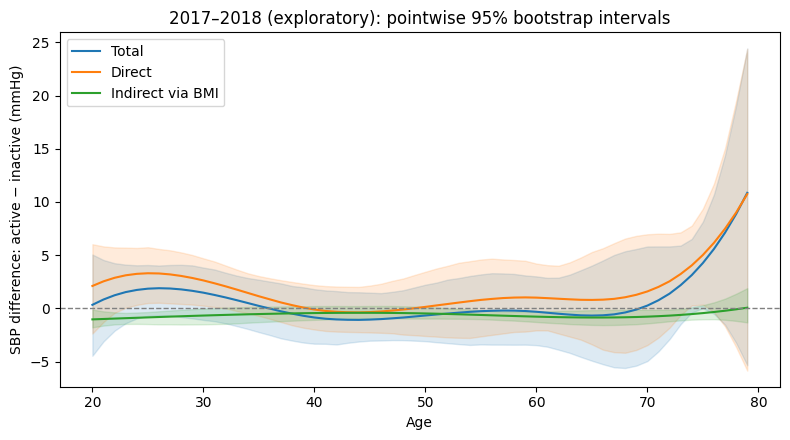

In [17]:
import matplotlib.pyplot as plt


def plot_by_age(intervals, out_dir, title):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for effect, label, color in [
        ("total", "Total", "tab:blue"),
        ("direct", "Direct", "tab:orange"),
        ("indirect", "Indirect via BMI", "tab:green"),
    ]:
        curve = intervals.loc[intervals["effect"].eq(effect)]
        ax.plot(curve["age"], curve["estimate"], color=color, label=label)
        ax.fill_between(
            curve["age"], curve["lower_95"], curve["upper_95"], color=color, alpha=0.15
        )
    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.set(xlabel="Age", ylabel="SBP difference: active − inactive (mmHg)", title=title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_dir / "activity_by_age_intervals.png", dpi=200)
    plt.show()


plot_by_age(
    intervals_by_age,
    results_dir,
    "2017–2018 (exploratory): pointwise 95% bootstrap intervals",
)

## Holdout inference: 2015–2016 cycle

Everything above, including the AIC selection, uses 2017–2018 and is **exploratory**: that cycle chose the model. Here the frozen specification is fitted unchanged to an independent cycle. It keeps the same formulas (including activity × BMI), category coding, income groups, and the 2017 spline knots, and nothing is re-selected. **The memo's inferential results come from this section.**

- Variable definitions are assumed identical across cycles.
- 2015–2016 is analyzed with its own two-year examination weights and design: 15 strata (119–133), each with 2 PSUs. The cycles are not pooled, so no weight adjustment is needed.
- The first cell checks that the cycle-building function exactly reproduces the 2017 sample above. Any missing 2015 files (`PAQ_I`, `DBQ_I`) are downloaded from CDC on first run.


In [18]:
def prepare_cycle(data_dir, suffix, year):
    """Build the complete-case sample for one NHANES cycle with the 2017 variable definitions.

    Missing files are downloaded once from CDC and cached next to the others.
    Returns the complete-case frame and the cycle's strata/PSUs.
    """

    def read(name):
        path = data_dir / f"{name}_{suffix}.csv.gz"
        if not path.exists():
            from io import BytesIO
            import requests

            url = f"https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/{year}/DataFiles/{name}_{suffix}.xpt"
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            pd.read_sas(BytesIO(response.content), format="xport").to_csv(
                path, index=False
            )
        return pd.read_csv(path)

    demo_cycle = read("DEMO")
    frame = demo_cycle[
        [
            "SEQN",
            "WTMEC2YR",
            "SDMVSTRA",
            "SDMVPSU",
            "RIDAGEYR",
            "INDHHIN2",
            "RIDRETH3",
            "RIAGENDR",
        ]
    ].copy()
    for name, cols in [
        ("BMX", ["BMXBMI"]),
        ("BPX", ["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"]),
        ("PAQ", ["PAQ635"]),
        ("DBQ", ["DBQ700"]),
    ]:
        frame = frame.merge(
            read(name)[["SEQN"] + cols], on="SEQN", how="left", validate="one_to_one"
        )

    frame["active_transport"] = frame["PAQ635"].map({1: 1, 2: 0})
    readings = frame[["BPXSY1", "BPXSY2", "BPXSY3", "BPXSY4"]]
    frame["mean_sbp"] = readings.where(readings > 0).mean(axis=1)

    adults_cycle = frame.loc[frame["RIDAGEYR"].between(20, 79)].copy()
    adults_cycle["DBQ700"] = adults_cycle["DBQ700"].where(
        adults_cycle["DBQ700"].isin([1, 2, 3, 4, 5])
    )
    adults_cycle["income_group"] = adults_cycle["INDHHIN2"].map(income_groups)
    adults_cycle["RIAGENDR"] = adults_cycle["RIAGENDR"].where(
        adults_cycle["RIAGENDR"].isin([1, 2])
    )
    adults_cycle["RIDRETH3"] = adults_cycle["RIDRETH3"].where(
        adults_cycle["RIDRETH3"].isin([1, 2, 3, 4, 6, 7])
    )
    adults_cycle["BMXBMI"] = adults_cycle["BMXBMI"].where(adults_cycle["BMXBMI"] > 0)
    cc_cycle = (
        adults_cycle
        .dropna(subset=model_columns)
        .loc[lambda x: x["WTMEC2YR"] > 0]
        .copy()
    )
    design_cycle = demo_cycle[["SDMVSTRA", "SDMVPSU"]].drop_duplicates().dropna()
    return cc_cycle.reset_index(drop=True), design_cycle


# Check: the function reproduces the 2017 analysis sample built step by step above.
check, _ = prepare_cycle(data_dir, "J", 2017)
pd.testing.assert_frame_equal(
    check[["SEQN"] + model_columns].sort_values("SEQN").reset_index(drop=True),
    cc[["SEQN"] + model_columns].sort_values("SEQN").reset_index(drop=True),
    check_dtype=False,
)

cc_2015, design_2015 = prepare_cycle(Path("../2015"), "I", 2015)
print(
    f"2015–2016 complete cases: {len(cc_2015):,}; "
    f"{design_2015['SDMVSTRA'].nunique()} strata, {len(design_2015)} PSUs"
)
display(
    cc_2015["active_transport"]
    .map({0: "No", 1: "Yes"})
    .value_counts()
    .rename("Participants")
)

2015–2016 complete cases: 4,459; 15 strata, 30 PSUs


active_transport
No     3489
Yes     970
Name: Participants, dtype: int64

### Frozen models on 2015–2016: survey bootstrap and coefficients

Same Rao–Wu bootstrap (B = 2,000), now resampling 2015–2016 PSUs within strata.


In [19]:
holdout_dir = results_dir / "holdout_2015"
holdout_dir.mkdir(parents=True, exist_ok=True)
boot_2015 = survey_bootstrap(cc_2015, design_2015, *model_matrices(cc_2015), seed=2015)
sbp_coefficients_2015, bmi_coefficients_2015 = coefficient_tables(
    boot_2015, holdout_dir
)

2000 bootstrap replicates in 8 s; 15 strata, 30 PSUs; BMI residual SD = 6.66 kg/m²
Outcome model: mean SBP (mmHg). Survey bootstrap SEs and percentile 95% intervals.


,term,estimate,bootstrap_SE,lower_95,upper_95
coefficient,,,,,
Intercept,Intercept,106.068,1.999,102.439,110.153
C(DBQ700)[T.2.0],Diet quality: Very good,0.810,1.319,-1.958,3.217
C(DBQ700)[T.3.0],Diet quality: Good,0.128,1.145,-2.170,2.265
C(DBQ700)[T.4.0],Diet quality: Fair,-0.262,0.854,-1.854,1.406
C(DBQ700)[T.5.0],Diet quality: Poor,2.118,1.127,-0.043,4.329
C(income_group)[T.2.0],"Household income: Medium ($20k–74,999)",-1.607,0.760,-3.016,-0.025
C(income_group)[T.3.0],Household income: High (≥$75k),-2.664,0.645,-3.897,-1.368
C(RIAGENDR)[T.2.0],Sex: Female,-4.796,0.601,-5.934,-3.620
C(RIDRETH3)[T.2.0],Race/ethnicity: Other Hispanic,0.053,0.949,-2.145,1.496


Mediator model: BMI (kg/m²). Survey bootstrap SEs and percentile 95% intervals.


,term,estimate,bootstrap_SE,lower_95,upper_95
coefficient,,,,,
Intercept,Intercept,24.725,1.314,22.332,27.345
C(DBQ700)[T.2.0],Diet quality: Very good,1.439,0.530,0.464,2.445
C(DBQ700)[T.3.0],Diet quality: Good,2.874,0.333,2.271,3.527
C(DBQ700)[T.4.0],Diet quality: Fair,4.634,0.360,3.933,5.327
C(DBQ700)[T.5.0],Diet quality: Poor,6.471,0.906,4.656,8.089
C(income_group)[T.2.0],"Household income: Medium ($20k–74,999)",-0.194,0.383,-0.907,0.553
C(income_group)[T.3.0],Household income: High (≥$75k),-0.699,0.446,-1.537,0.163
C(RIAGENDR)[T.2.0],Sex: Female,0.440,0.262,-0.066,0.936
C(RIDRETH3)[T.2.0],Race/ethnicity: Other Hispanic,-0.522,0.588,-1.433,0.725


### Holdout mediation effects

Population-averaged effects, then effects by age, from the same imputation estimator of equations (17)–(19).


In [20]:
mediation_summary_2015 = population_summary(boot_2015, holdout_dir)

Computed in 0 s


,estimate,bootstrap_SE,lower_95,upper_95
Total (mmHg),0.748,0.704,-0.656,2.001
Direct (mmHg),1.371,0.737,-0.093,2.688
Indirect via BMI (mmHg),-0.638,0.149,-0.921,-0.332
BMI difference (kg/m²),-1.360,0.345,-2.020,-0.672
"BMI → SBP slope, inactive (mmHg per kg/m²)",0.469,0.049,0.376,0.566
"BMI → SBP slope, active (mmHg per kg/m²)",0.459,0.121,0.211,0.676


Total − (direct + indirect) = 0.0143 mmHg


Computed in 18 s


,Total,Direct,Indirect via BMI,BMI difference
age,,,,
20,"-1.63 (-6.09, 2.36)","-0.82 (-5.23, 3.31)","-0.83 (-2.19, 0.35)","-1.77 (-4.42, 0.76)"
30,"-1.10 (-3.11, 1.09)","-0.42 (-2.22, 1.52)","-0.69 (-1.03, -0.33)","-1.47 (-2.18, -0.74)"
40,"1.21 (-1.69, 3.89)","1.69 (-1.10, 4.24)","-0.49 (-0.79, -0.13)","-1.04 (-1.84, -0.25)"
50,"3.10 (-0.01, 5.74)","3.48 (0.58, 5.86)","-0.39 (-0.94, 0.16)","-0.84 (-2.09, 0.33)"
60,"1.81 (-0.89, 4.43)","2.34 (-0.26, 4.96)","-0.55 (-1.08, -0.05)","-1.17 (-2.40, -0.10)"
70,"-1.17 (-5.88, 3.79)","-0.23 (-4.64, 4.40)","-0.97 (-1.67, -0.25)","-2.07 (-3.57, -0.54)"
79,"6.36 (-9.17, 16.61)","7.89 (-7.46, 18.49)","-1.57 (-3.47, 0.22)","-3.34 (-7.32, 0.47)"


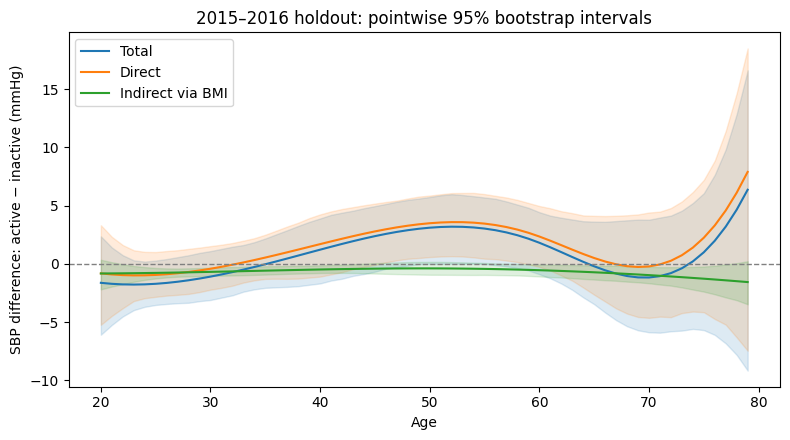

In [21]:
intervals_by_age_2015 = effects_by_age(boot_2015, holdout_dir)
plot_by_age(
    intervals_by_age_2015,
    holdout_dir,
    "2015–2016 holdout: pointwise 95% bootstrap intervals",
)

### Predicted BMI by age and active transportation

The mediator model on its own: predicted mean BMI at each age with active transportation set to no and to yes. Everyone in the 2015–2016 sample is assigned each age and exposure value, and predictions are averaged with examination weights, so the controls stay at the sample's distribution. The vertical gap between the curves is the age-specific BMI difference (the first link of the indirect pathway). Bands are pointwise 95% bootstrap intervals for each curve. Overlapping bands do **not** imply the gap is zero, because the interval for a difference is narrower than the two curves' intervals suggest.

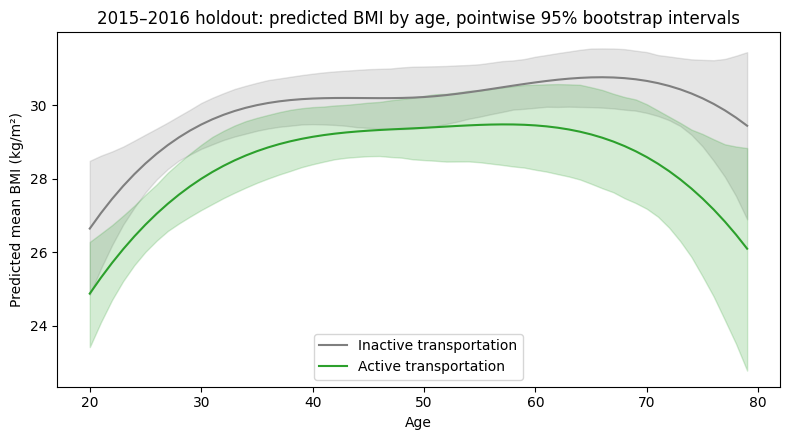

transport,Active,Inactive
age,,
20,24.88,26.65
30,28.00,29.47
40,29.14,30.18
50,29.38,30.22
60,29.45,30.62
70,28.59,30.66
79,26.10,29.44


In [22]:
def bmi_by_age(boot, out_dir, title):
    """Predicted mean BMI by age with active transportation set to no and to yes.

    Everyone in the sample is assigned each age and each exposure value. The fitted
    BMI model predicts their BMI, and the predictions are averaged with examination
    weights. The controls are held at the sample's own distribution. Intervals are
    pointwise 95% bootstrap percentiles.
    """
    rows = []
    for age in range(20, 80):
        for x, label in [(0, "Inactive"), (1, "Active")]:
            X = np.asarray(build_design_matrices(
                [bmi_spec], boot["frame"].assign(RIDAGEYR=age, active_transport=x))[0])
            point = np.average(X @ boot["point_bmi"], weights=boot["weights"])
            preds = X @ boot["boot_bmi"].T                      # (n, B)
            reps = (boot["boot_weights"] * preds).sum(0) / boot["boot_weights"].sum(0)
            lower, upper = np.percentile(reps, [2.5, 97.5])
            rows.append({"age": age, "transport": label, "mean_bmi": point,
                         "lower_95": lower, "upper_95": upper})
    curves = pd.DataFrame(rows)
    curves.to_csv(out_dir / "bmi_by_age.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for label, color in [("Inactive", "tab:gray"), ("Active", "tab:green")]:
        curve = curves.loc[curves["transport"].eq(label)]
        ax.plot(curve["age"], curve["mean_bmi"], color=color, label=f"{label} transportation")
        ax.fill_between(curve["age"], curve["lower_95"], curve["upper_95"], color=color, alpha=0.2)
    ax.set(xlabel="Age", ylabel="Predicted mean BMI (kg/m²)", title=title)
    ax.legend()
    fig.tight_layout()
    fig.savefig(out_dir / "bmi_by_age.png", dpi=200)
    plt.show()
    return curves


bmi_curves_2015 = bmi_by_age(boot_2015, holdout_dir, "2015–2016 holdout: predicted BMI by age, pointwise 95% bootstrap intervals")
display(bmi_curves_2015.loc[bmi_curves_2015["age"].isin([20, 30, 40, 50, 60, 70, 79])]
        .pivot(index="age", columns="transport", values="mean_bmi").round(2))

### Memo table

Effects in mmHg (active − inactive) with pointwise 95% bootstrap intervals at selected ages, plus the population-averaged effect over the sample's age distribution.

In [23]:
def interval_cell(table, row):
    r = table.loc[row]
    return f"{r.estimate:.2f} ({r.lower_95:.2f}, {r.upper_95:.2f})"


# Memo table: effects at selected ages plus the population-averaged effect (2015–2016 holdout).
memo_effects = {"total": "Total", "direct": "Direct", "indirect": "Indirect via BMI"}
selected = intervals_by_age_2015.loc[intervals_by_age_2015["age"].isin([20, 30, 40, 50, 60, 70, 79])
                                     & intervals_by_age_2015["effect"].isin(list(memo_effects))]
memo_table = (selected.assign(cell=selected.apply(fmt, axis=1))
              .pivot(index="age", columns="effect", values="cell")[list(memo_effects)]
              .rename(columns=memo_effects))
memo_table.index = memo_table.index.astype(str)
memo_table.loc["All ages (average)"] = [
    interval_cell(mediation_summary_2015, row)
    for row in ["Total (mmHg)", "Direct (mmHg)", "Indirect via BMI (mmHg)"]]
memo_table.index.name = "Age"
memo_table.to_csv(holdout_dir / "memo_table.csv")
display(memo_table)

effect,Total,Direct,Indirect via BMI
Age,,,
20,"-1.63 (-6.09, 2.36)","-0.82 (-5.23, 3.31)","-0.83 (-2.19, 0.35)"
30,"-1.10 (-3.11, 1.09)","-0.42 (-2.22, 1.52)","-0.69 (-1.03, -0.33)"
40,"1.21 (-1.69, 3.89)","1.69 (-1.10, 4.24)","-0.49 (-0.79, -0.13)"
50,"3.10 (-0.01, 5.74)","3.48 (0.58, 5.86)","-0.39 (-0.94, 0.16)"
60,"1.81 (-0.89, 4.43)","2.34 (-0.26, 4.96)","-0.55 (-1.08, -0.05)"
70,"-1.17 (-5.88, 3.79)","-0.23 (-4.64, 4.40)","-0.97 (-1.67, -0.25)"
79,"6.36 (-9.17, 16.61)","7.89 (-7.46, 18.49)","-1.57 (-3.47, 0.22)"
All ages (average),"0.75 (-0.66, 2.00)","1.37 (-0.09, 2.69)","-0.64 (-0.92, -0.33)"


### 2017 (selection) vs. 2015 (holdout)

Estimates (95% bootstrap intervals) from both cycles side by side. Agreement suggests the 2017 results were not produced by the specification search. The activity × BMI row tests whether the interaction AIC picked in 2017 replicates.


In [24]:
interaction = "active_transport:BMXBMI"
rows = list(mediation_summary.index)
comparison = pd.DataFrame(
    {
        "2017–2018 (model selection)": [
            interval_cell(mediation_summary, r) for r in rows
        ],
        "2015–2016 (holdout inference)": [
            interval_cell(mediation_summary_2015, r) for r in rows
        ],
    },
    index=rows,
)
if interaction in sbp_coefficients.index:
    comparison.loc["Active × BMI coefficient (mmHg per kg/m²)"] = [
        interval_cell(sbp_coefficients, interaction),
        interval_cell(sbp_coefficients_2015, interaction),
    ]
comparison.loc["Complete cases (n)"] = [f"{len(cc):,}", f"{len(cc_2015):,}"]
comparison.to_csv(holdout_dir / "cycle_comparison.csv")
display(comparison)

,2017–2018 (model selection),2015–2016 (holdout inference)
Total (mmHg),"0.42 (-0.80, 1.65)","0.75 (-0.66, 2.00)"
Direct (mmHg),"1.52 (0.24, 2.99)","1.37 (-0.09, 2.69)"
Indirect via BMI (mmHg),"-0.64 (-0.97, -0.32)","-0.64 (-0.92, -0.33)"
BMI difference (kg/m²),"-1.59 (-2.35, -0.78)","-1.36 (-2.02, -0.67)"
"BMI → SBP slope, inactive (mmHg per kg/m²)","0.40 (0.28, 0.54)","0.47 (0.38, 0.57)"
"BMI → SBP slope, active (mmHg per kg/m²)","0.69 (0.53, 0.90)","0.46 (0.21, 0.68)"
Active × BMI coefficient (mmHg per kg/m²),"0.29 (0.06, 0.55)","-0.01 (-0.23, 0.20)"
Complete cases (n),"4,014","4,459"
